In [49]:
from pathlib import Path
import nilearn
from nilearn import datasets, plotting, image
from nilearn.image import mean_img
from nilearn.maskers import NiftiLabelsMasker
import nibabel as nib
import numpy as np
import pandas as pd
import scipy
import matplotlib

In [50]:
#set directory
func_dir = Path("/Users/pranjaliektare/ds006039/sub-1004/func")

#we need to filter out other files and only get the beginning with wrsub
bold_files = sorted(func_dir.glob("wrsub-1004_task-aim_run-*_bold.nii"))
rp_files = sorted(func_dir.glob("rp_sub-1004_task-aim_run-*_bold.txt"))
print(len(bold_files), len(rp_files)) #should be 8 each
for b in bold_files:
    print(b.name)
for r in rp_files:
    print(r.name)

8 8
wrsub-1004_task-aim_run-01_bold.nii
wrsub-1004_task-aim_run-02_bold.nii
wrsub-1004_task-aim_run-03_bold.nii
wrsub-1004_task-aim_run-04_bold.nii
wrsub-1004_task-aim_run-05_bold.nii
wrsub-1004_task-aim_run-06_bold.nii
wrsub-1004_task-aim_run-07_bold.nii
wrsub-1004_task-aim_run-08_bold.nii
rp_sub-1004_task-aim_run-01_bold.txt
rp_sub-1004_task-aim_run-02_bold.txt
rp_sub-1004_task-aim_run-03_bold.txt
rp_sub-1004_task-aim_run-04_bold.txt
rp_sub-1004_task-aim_run-05_bold.txt
rp_sub-1004_task-aim_run-06_bold.txt
rp_sub-1004_task-aim_run-07_bold.txt
rp_sub-1004_task-aim_run-08_bold.txt


In [48]:
bold_paths = [str(f) for f in bold_files]
#checking no of voxels
meansub_image_1 = nib.load("/Users/pranjaliektare/ds006039/sub-1004/func/meansub-1004_task-aim_run-01_bold.nii")
voxels = (meansub_image_1).header.get_zooms()
print(voxels)

HIGH_PASS = 1/128 # 128 sec converted to HZ source https://www.fil.ion.ucl.ac.uk/spm/docs/manual/fmri_spec/fmri_spec/
TR = 1.87 #timeresolution in seconds, in json files metadata check RepetitionTime
THRESHOLD = 0.5 #threshold for fd in mm, set as per task fMRI guidelines by Van Djik et al 2012
VOXELS = voxels

motion = [np.loadtxt(r) for r in rp_files]
print([m.shape for m in motion])          # each (188, 6)


(np.float32(1.704918), np.float32(1.7049179), np.float32(1.6999999))
[(188, 6), (188, 6), (188, 6), (188, 6), (188, 6), (188, 6), (188, 6), (188, 6)]


[fetch_atlas_schaefer_2018] Dataset directory found: /Users/pranjaliektare/nilearn_data/schaefer_2018


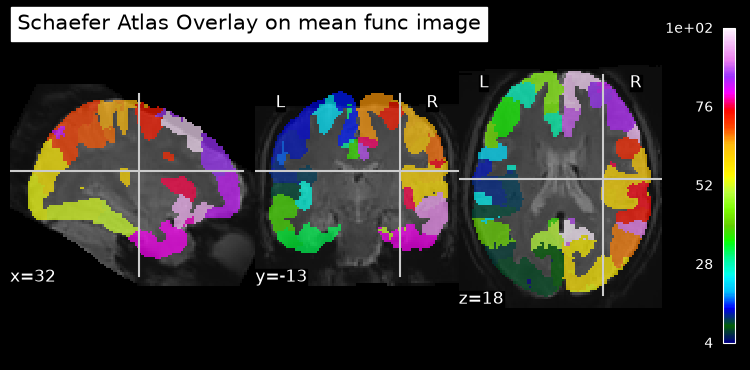

In [51]:
#import the schafer atlas for overlay onto mean image 
from nilearn.image import mean_img
atlas = datasets.fetch_atlas_schaefer_2018(n_rois=100)
meanfuncimage = mean_img(bold_files)

#resampling schafer atlas to match 1.7mm voxel grid
from nilearn.image import resample_to_img
resampled_atlas = resample_to_img(
    source_img = atlas.maps,
    target_img = meanfuncimage,
    interpolation = "nearest",
)

plotting.plot_roi(
    roi_img = resampled_atlas,
    bg_img = meanfuncimage,
    title="Schaefer Atlas Overlay on mean func image")

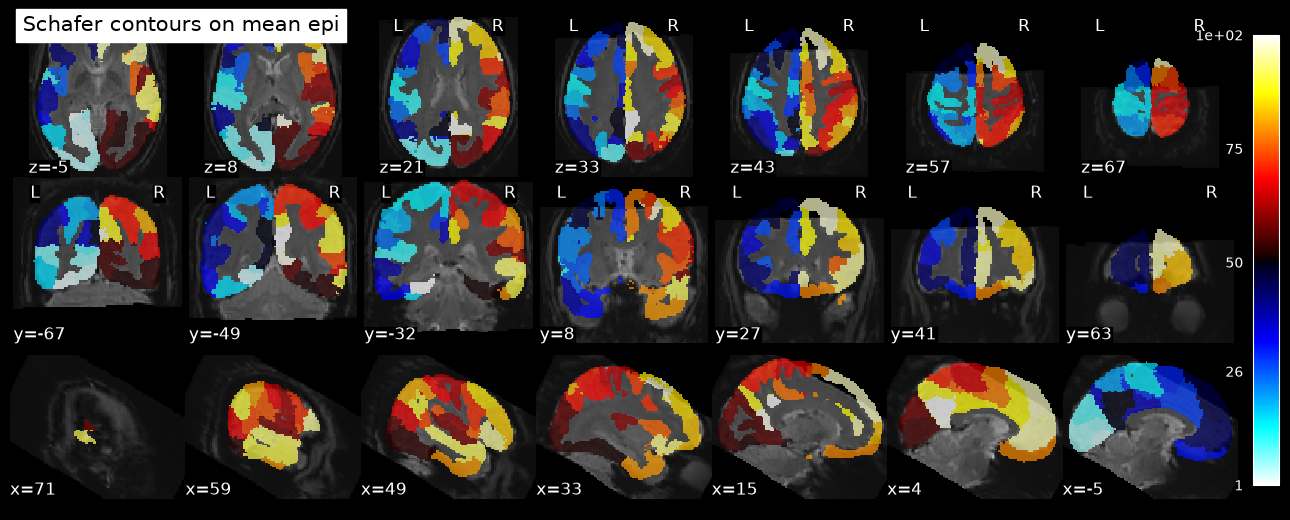

In [52]:
#plottting schafer atlas contour lines on mean image
plotting.plot_roi(
    roi_img=resampled_atlas,
    bg_img= meanimage,
    cmap = "cold_hot",
    display_mode = "mosaic",
    view_type = "continuous", #countours did not work properly
    title = "Schafer contours on mean epi",
    colorbar = True
)

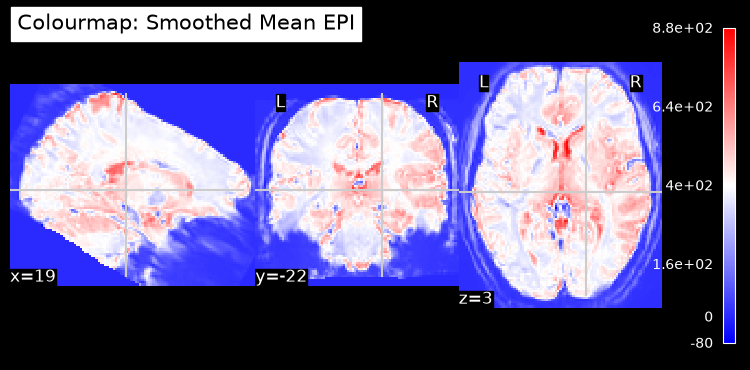

In [53]:
#plotting colourmaps
from matplotlib.cm import bwr
import matplotlib.pyplot as plt
from nilearn.image import mean_img
from nilearn.plotting import plot_epi, show


plot_epi(
    meanfuncimage,
    title = "Colourmap: Smoothed Mean EPI",
    cmap = bwr
)

In [54]:
# sorting out the events file
events = pd.read_csv("/Users/pranjaliektare/ds006039/sub-1004/func/sub-1004_task-aim_events.tsv", sep="\t") #loading events
# AC test trials show two objects (no face or scene), so they get their own label
events["trial_type"] = np.where(events["trialtype"] == "AC", "AC", events["category"])

blocks = sorted(events["block"].unique())
print(*blocks)

1 2 3 4 5 6 7 8


In [77]:
#sorting out columns
events["trial_type"] = np.where(
    events["trialtype"] == np.where(events["trial_type"] + "-" + events["phase"] == "study" + "_" + events["category"])
)
events_per_run = [events.loc[events["block"] == b, cols] for b in blocks]
print(events_per_run)


ValueError: Lengths of operands do not match: 320 != 1

In [70]:
#first level model 

from nilearn.glm.first_level import FirstLevelModel

fmri_glm = FirstLevelModel(
    smoothing_fwhm=3*1.704918, # 3 times voxel size source http://jpeelle.net/mri/image_processing/smoothing.html
    t_r=TR,
    hrf_model="spm + derivative",
    drift_model="cosine",
    high_pass=HIGH_PASS,
    verbose=1,
)
fmri_glm.fit(bold_paths, events=events_per_run, confounds=motion)
print(len(fmri_glm.design_matrices_))                       # should be 8
print(fmri_glm.design_matrices_[0].columns.tolist()[:6])    # check column names and order

[FirstLevelModel.fit] Computing run 1 out of 8 runs (go take a coffee, a big one).
[FirstLevelModel.fit] Performing mask computation.
[FirstLevelModel.fit] Masking took 5 seconds.
[FirstLevelModel.fit] Performing GLM computation.
[FirstLevelModel.fit] GLM took 5 seconds.
[FirstLevelModel.fit] Computing run 2 out of 8 runs (00 HR 01 MIN 20 SEC remaining).
[FirstLevelModel.fit] Performing mask computation.
[FirstLevelModel.fit] Masking took 5 seconds.
[FirstLevelModel.fit] Performing GLM computation.
[FirstLevelModel.fit] GLM took 5 seconds.
[FirstLevelModel.fit] Computing run 3 out of 8 runs (00 HR 01 MIN 09 SEC remaining).
[FirstLevelModel.fit] Performing mask computation.
[FirstLevelModel.fit] Masking took 5 seconds.
[FirstLevelModel.fit] Performing GLM computation.
[FirstLevelModel.fit] GLM took 5 seconds.
[FirstLevelModel.fit] Computing run 4 out of 8 runs (00 HR 00 MIN 58 SEC remaining).
[FirstLevelModel.fit] Performing mask computation.
[FirstLevelModel.fit] Masking took 5 seconds

KeyboardInterrupt: 

In [ ]:
con = ["study_Face" if b % 2 == 0 else "-study_Scene" for b in blocks]
z_study = glm_study.compute_contrast(con, output_type="z_score")

thr_map, thr = threshold_stats_img(z_study, alpha=0.05, height_control="fdr")
print("FDR z threshold:", thr)
plot_stat_map(z_study, bg_img=mean_func, threshold=3.1, display_mode="z",
              cut_coords=5, title="Study phase: Face - Scene (between runs)")
plt.show()

In [ ]:
#Face - Scene (a BETWEEN-run contrast: odd runs = Scene, even runs = Face)
# One contrast per run, because no run contains both conditions.
contrasts = ["Face" if b%2 == 0 else "Scene" for b in blocks]
z_map = fmri_glm.compute_contrast(contrasts, output_type="z_score")

from nilearn.glm import threshold_stats_img
thr_map, thr = threshold_stats_img(z_map, alpha=0.05, height_control="fdr")
print("FDR z threshold (inf = nothing survives):", thr)

plot_stat_map(
    z_map, bg_img=meanfuncimage, threshold=3.1,       # 3.1 is an uncorrected display threshold
    display_mode="z", cut_coords=5, title="Face - Scene (between runs)",
)

FDR z threshold (inf = nothing survives): 2.2802678373779846


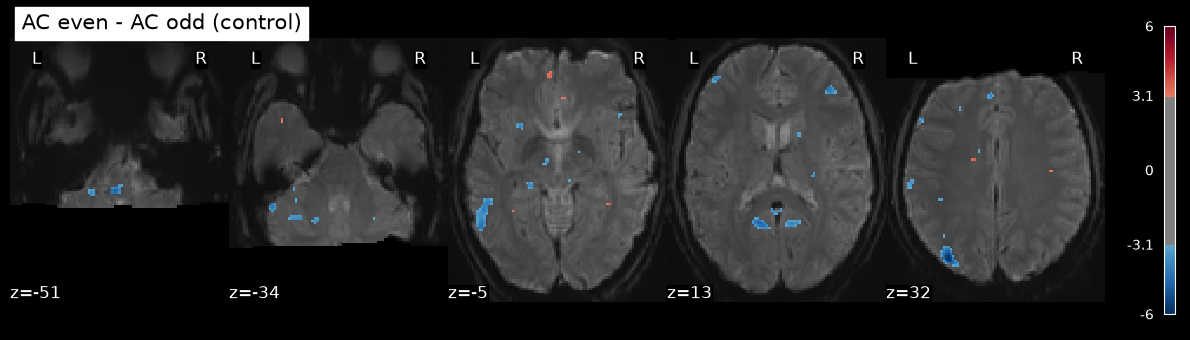

In [ ]:
con_ac = ["AC" if b % 2 == 0 else "-AC" for b in blocks]
z_ac = fmri_glm.compute_contrast(con_ac, output_type="z_score")
plot_stat_map(z_ac, bg_img=meanfuncimage, threshold=3.1, display_mode="z",
              cut_coords=5, title="AC even - AC odd (control)")

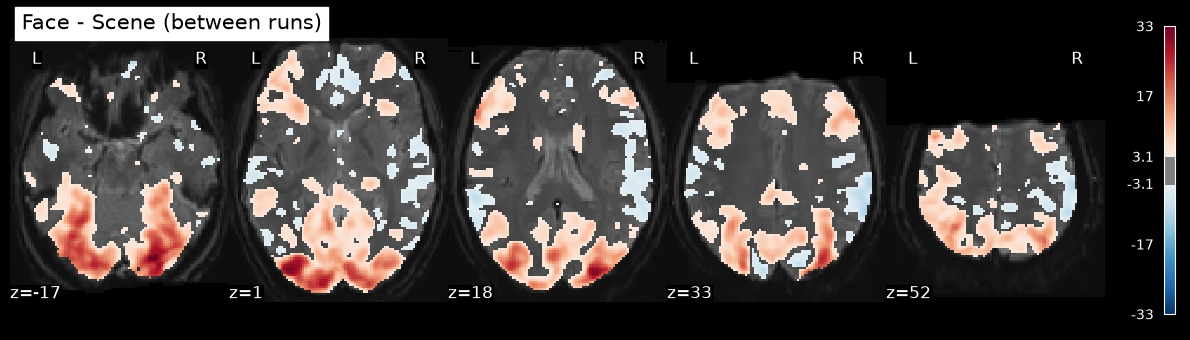

wrsub-1004_task-aim_run-01_bold.nii (188, 100)
wrsub-1004_task-aim_run-02_bold.nii (188, 100)
wrsub-1004_task-aim_run-03_bold.nii (188, 100)
wrsub-1004_task-aim_run-04_bold.nii (188, 100)
wrsub-1004_task-aim_run-05_bold.nii (188, 100)
wrsub-1004_task-aim_run-06_bold.nii (188, 100)
wrsub-1004_task-aim_run-07_bold.nii (188, 100)
wrsub-1004_task-aim_run-08_bold.nii (188, 100)


Text(0, 0.5, 'Signal (z-scored)')

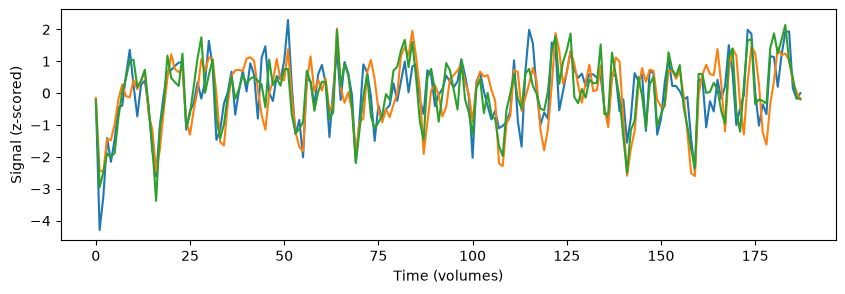

In [60]:
#ROI time series (Schaefer 100), one run at a time
# extract regionwise signlas and clean the data
masker = NiftiLabelsMasker(
    labels_img=atlas.maps,
    labels = None,
    mask_img = None,
    standardize="zscore_sample",
    detrend=True,        # removes the slow linear drift
    high_pass=HIGH_PASS,      # 128 sec converted to HZ source https://www.fil.ion.ucl.ac.uk/spm/docs/manual/fmri_spec/fmri_spec/
    t_r=TR,
)

all_ts = {}
for f, rp in zip(bold_files, motion):
    ts = masker.fit_transform(str(f), confounds=rp)
    all_ts[f.name] = ts
    print(f.name, ts.shape)                            # (188, 100)
 
plt.figure(figsize=(10, 3))
plt.plot(all_ts[bold_files[0].name][:, :3])
plt.xlabel("Time (volumes)")
plt.ylabel("Signal (z-scored)")

In [ ]:
#ward parce;;ation for visualisation
from nilearn.regions import Parcellations

ward = Parcellations(
    method="ward",
    n_parcels=1000,
    smoothing_fwhm=3*1.704918, # 3 times voxel size source http://jpeelle.net/mri/image_processing/smoothing.html
    detrend=True,
    t_r = TR,
    high_pass = HIGH_PASS,
    memory="nilearn_cache",
    memory_level=1,
    verbose=1,
)

ward.fit(bold_paths)


[Parcellations.fit] Loading data


KeyboardInterrupt: 

In [ ]:
plotting.plot_roi(
    ward.labels_img_, bg_img=meanfuncimage, display_mode="xz", title="Ward parcellation (1000)"
)
plotting.plot.show()